# EDA 4 · Events: patches and online players

1. **Patches**: how reviews and the 👍 share move in the 14 days before and after a patch, by patch size; per game; the worst patches.
2. **Online players and reviews**: daily for the last months, monthly over the full history, and what moves first (cross-correlation, Granger tests).

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import PercentFormatter
from statsmodels.tsa.stattools import grangercausalitytests

from src.config import FEATURES_DIR, game_names
from src.features.daily import collection, daily_series, online_players, patch_days
from src.features.events import SIZES, event_study, patches, study_patches
from src.features.monthly import month_changes, monthly_panel
from src.viz.charts import SERIES_COLOR, per_game_panels, use_style

use_style()
warnings.filterwarnings("ignore", category=FutureWarning, module="statsmodels")
SIZE_COLORS = {"hotfix": "#9aa5b1", "update": "#2a78d6", "major": "#e34948"}

In [2]:
BEFORE, AFTER = 14, 14      # days shown around a patch
BASELINE = (-14, -1)        # days a patch is compared to
POST = (0, 6)               # "after the patch": the patch day and the 6 days after
QUIET_DAYS = 14             # isolated: no other patch of the game in these days before
LAUNCH_DAYS = 45            # patches this close after a game's first review or release are left out
MIN_BASELINE_REVIEWS = 70   # a patch needs this many reviews in its baseline (stable 👍 share)
MAX_LAG = 14                # days for cross-correlation
TOP_GAMES = 6               # games in the daily online charts (most reviews)

## The data

In [3]:
names = game_names()
collected = collection()
games = collected.index[collected["complete"].ne(False)]
series = daily_series(games)
online = online_players(games)
all_patches = patches(games)
all_patches.to_parquet(FEATURES_DIR / "patches.parquet")  # for the models: official patches with size
events = study_patches(series, QUIET_DAYS, LAUNCH_DAYS, AFTER, BASELINE, MIN_BASELINE_REVIEWS)
print(f"{len(all_patches):,} official patch days in {all_patches['appid'].nunique()} games; {len(events):,} for the event study")
pd.crosstab(all_patches["appid"].map(names), all_patches["size"]).reindex(columns=SIZES).assign(
    studied=events.groupby("appid").size().rename(index=names)).fillna(0).astype(int).sort_values("studied", ascending=False).T

4,012 official patch days in 58 games; 1,066 for the event study


appid,Dead by Daylight,Brawlhalla,Dota 2,Stellaris,Factorio,Hearts of Iron IV,Phasmophobia,The Forest,FOR HONOR™,RimWorld,...,Marvel Rivals,Hollow Knight: Silksong,ARC Raiders,Balatro,Destiny 2,It Takes Two,Slay the Spire 2,THE FINALS,MECCHA CHAMELEON,Dirt Clicker
size,,,,,,,,,,,,,,,,,,,,,
hotfix,89,60,31,44,70,33,34,105,5,23,...,23,0,10,2,0,0,9,22,6,3
update,2,124,72,79,155,61,6,40,10,45,...,52,0,2,3,0,0,2,17,10,4
major,58,68,15,51,43,20,90,24,31,18,...,18,5,47,6,1,2,14,117,33,2
studied,64,63,62,61,58,51,46,40,37,36,...,2,2,1,1,1,1,1,1,0,0


## 1. Reviews and 👍 share around patches

For every patch: reviews per day (as log) and the daily 👍 share, minus their mean over days −14 to −1. The lines are the mean over patches with a 95% band.

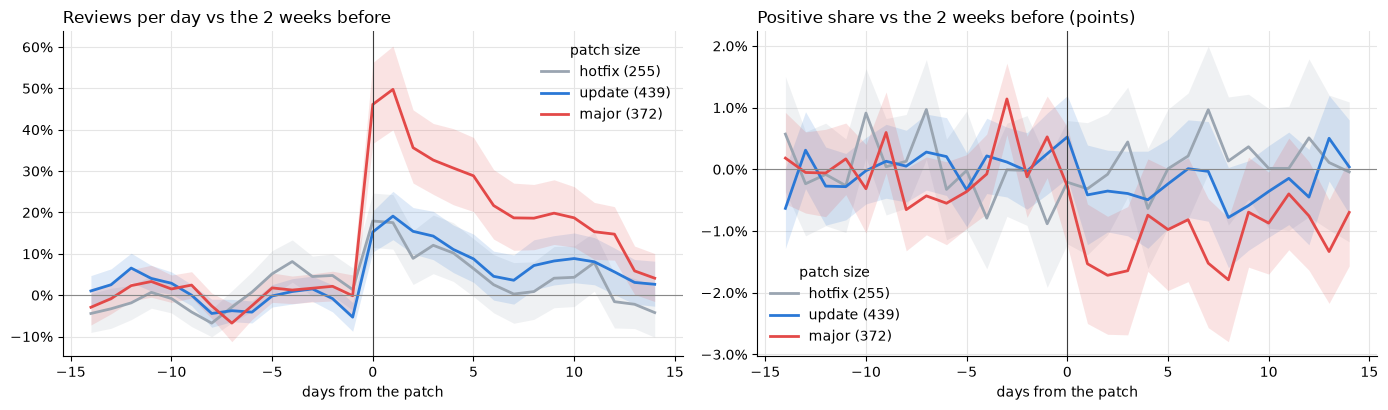

In [4]:
log_reviews = np.log1p(series["n"])
around = {"reviews": event_study(log_reviews, events, BEFORE, AFTER, BASELINE),
          "positive": event_study(series["positive"], events, BEFORE, AFTER, BASELINE)}


def mean_path(study, event_ids):
    d = study[study["event"].isin(event_ids)].groupby("offset")["change"]
    return pd.DataFrame({"mean": d.mean(), "ci": 1.96 * d.std() / np.sqrt(d.count())})


fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
for ax, (metric, study) in zip(axes, around.items(), strict=True):
    for size in SIZES:
        ids = events.index[events["size"] == size]
        path = mean_path(study, ids)
        if metric == "reviews":
            path = np.expm1(path["mean"]).to_frame("mean").assign(lo=np.expm1(path["mean"] - path["ci"]), hi=np.expm1(path["mean"] + path["ci"]))
        else:
            path = path.assign(lo=path["mean"] - path["ci"], hi=path["mean"] + path["ci"])
        ax.plot(path.index, path["mean"], color=SIZE_COLORS[size], label=f"{size} ({len(ids)})")
        ax.fill_between(path.index, path["lo"], path["hi"], color=SIZE_COLORS[size], alpha=0.15, linewidth=0)
    ax.axvline(0, color="#3c3c3c", linewidth=0.8)
    ax.axhline(0, color="#888888", linewidth=0.8)
    ax.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=0 if metric == "reviews" else 1))
    ax.set_xlabel("days from the patch")
    ax.legend(frameon=False, title="patch size")
axes[0].set_title("Reviews per day vs the 2 weeks before", loc="left")
axes[1].set_title("Positive share vs the 2 weeks before (points)", loc="left")
fig.tight_layout()

**Per patch**: the pooled 👍 share of the patch day and the 6 days after vs the baseline. A patch "hurts" if its 👍 share falls by more than 2 binomial standard errors, "helps" if it rises as much.

In [5]:
rows = []
for e in events.itertuples():
    base, post = (series.loc[e.appid].loc[e.day + pd.Timedelta(days=a) : e.day + pd.Timedelta(days=b), ["n", "n_positive"]].sum()
                  for a, b in (BASELINE, POST))
    days_base, days_post = BASELINE[1] - BASELINE[0] + 1, POST[1] - POST[0] + 1
    p0, p1 = base["n_positive"] / base["n"], (post["n_positive"] / post["n"]) if post["n"] else np.nan
    se = np.sqrt(max(p0 * (1 - p0), 0.0025) / max(post["n"], 1))
    rows.append({"event": e.Index, "appid": e.appid, "day": e.day, "size": e.size, "title": e.title,
                 "reviews_change": (post["n"] / days_post) / (base["n"] / days_base) - 1,
                 "positive_before": p0, "positive_change": p1 - p0, "z": (p1 - p0) / se})
effects = pd.DataFrame(rows)
effects["verdict"] = np.select([effects["z"] <= -2, effects["z"] >= 2], ["hurts", "helps"], default="no clear change")
summary = effects.groupby("size").agg(
    patches=("event", "size"), reviews_change=("reviews_change", "median"), positive_change=("positive_change", "mean"),
    hurts=("verdict", lambda v: (v == "hurts").mean()), helps=("verdict", lambda v: (v == "helps").mean()),
).reindex(SIZES)
summary.style.format({"reviews_change": "{:+.0%}", "positive_change": "{:+.1%}", "hurts": "{:.0%}", "helps": "{:.0%}"}).set_caption(
    "reviews_change: median change in reviews per day; positive_change: mean change in 👍 share (points)")

,patches,reviews_change,positive_change,hurts,helps
size,,,,,
hotfix,255,+4%,+0.1%,16%,16%
update,439,+3%,-0.4%,20%,13%
major,372,+19%,-1.4%,25%,15%


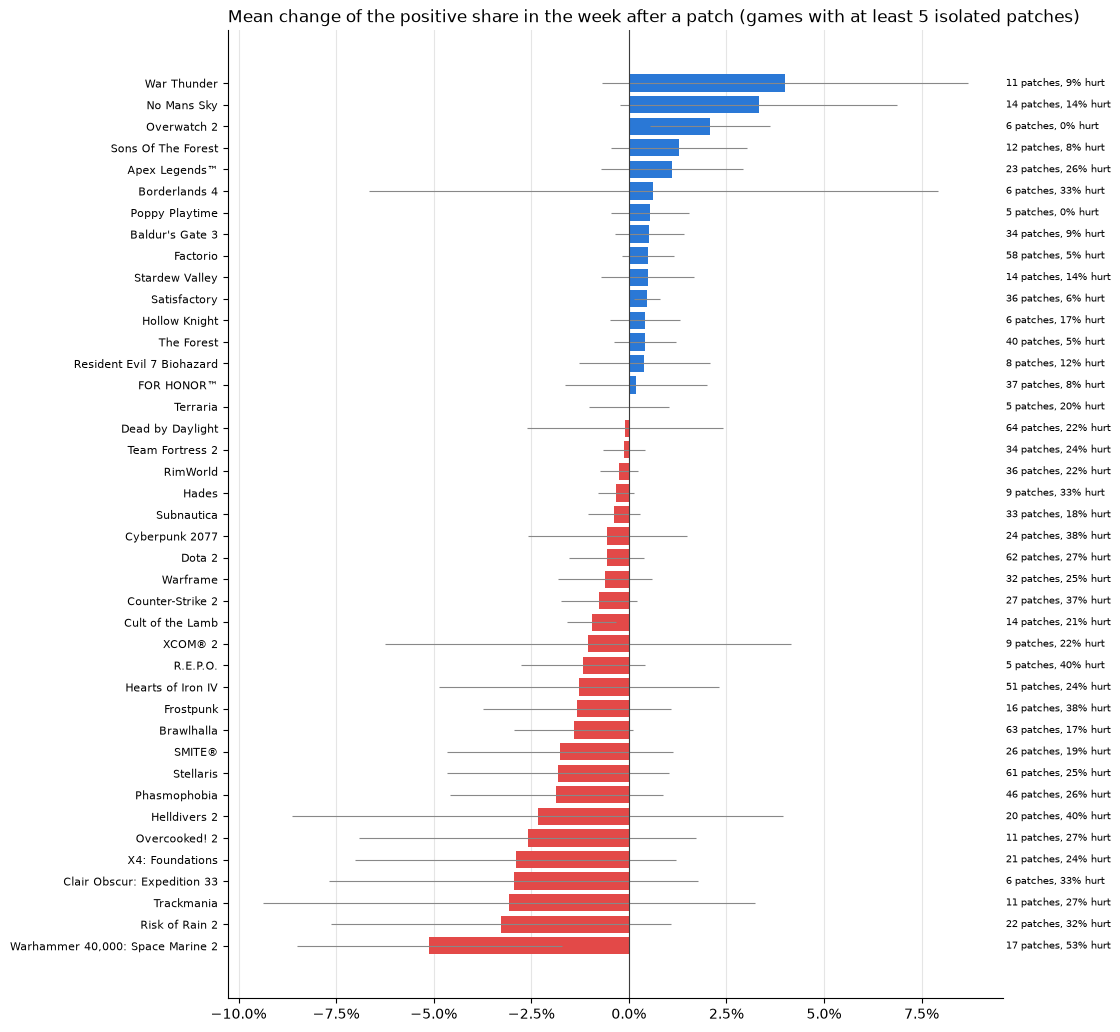

In [6]:
per_game = effects.groupby("appid").agg(patches=("event", "size"), positive_change=("positive_change", "mean"),
                                        se=("positive_change", lambda s: s.std() / np.sqrt(len(s))),
                                        hurts=("verdict", lambda v: (v == "hurts").mean()))
per_game = per_game[per_game["patches"] >= 5].sort_values("positive_change")
fig, ax = plt.subplots(figsize=(10, 0.27 * len(per_game) + 1.5))
ax.barh(per_game.index.map(names), per_game["positive_change"], xerr=1.96 * per_game["se"],
        color=np.where(per_game["positive_change"] < 0, "#e34948", SERIES_COLOR), error_kw={"elinewidth": 0.8, "ecolor": "#888888"})
for y, (n, hurts) in enumerate(zip(per_game["patches"], per_game["hurts"], strict=True)):
    ax.text(ax.get_xlim()[1], y, f" {n} patches, {hurts:.0%} hurt", va="center", fontsize=7)
ax.axvline(0, color="#3c3c3c", linewidth=0.8)
ax.xaxis.set_major_formatter(PercentFormatter(1.0, decimals=1))
ax.tick_params(axis="y", labelsize=8)
ax.grid(axis="y", visible=False)
ax.set_title("Mean change of the positive share in the week after a patch (games with at least 5 isolated patches)", loc="left");

In [7]:
worst = effects.nsmallest(12, "z").assign(game=lambda d: d["appid"].map(names))
print("Patches followed by the clearest 👍 drop")
display(worst[["game", "day", "size", "positive_before", "positive_change", "reviews_change", "title"]].style.format({
    "day": "{:%Y-%m-%d}", "positive_before": "{:.0%}", "positive_change": "{:+.1%}", "reviews_change": "{:+.0%}"}).hide(axis="index"))

Patches followed by the clearest 👍 drop


game,day,size,positive_before,positive_change,reviews_change,title
Hearts of Iron IV,2026-09-17,update,87%,-80.7%,+1487%,HOI IV | Patch 1.19.3
Risk of Rain 2,2024-08-27,major,94%,-45.5%,+1023%,[Patch Notes V1.3.1] Risk of Rain 2: Seekers of the Storm is Available Now!
Phasmophobia,2026-05-05,major,88%,-61.8%,+707%,Phasmophobia - Player Character Update 0.17.0.0
Dead by Daylight,2025-01-08,major,73%,-62.0%,+923%,8.5.0 | PTB Patch Notes
Helldivers 2,2024-08-06,major,83%,-33.2%,+502%,Patch 1.001.002 Escalation of Freedom | PATCH 1.001.002 explained
Helldivers 2,2026-04-28,major,65%,-40.3%,+479%,Machinery of Oppression: 6.2.2
Clair Obscur: Expedition 33,2025-12-12,major,96%,-14.1%,+6%,Patch 1.5.0 Notes!
Phasmophobia,2023-08-17,major,95%,-12.8%,+260%,Ascension | Major Update v0.9.0.0
Counter-Strike 2,2024-08-08,update,94%,-11.1%,-63%,Release Notes for 8/8/2024
"Warhammer 40,000: Space Marine 2",2024-12-10,major,96%,-19.9%,-78%,Update 5.0 is live!


## 2. Online players and reviews

**Daily, last months** (SteamCharts has daily data only from about August 2026): online players next to reviews (7-day mean) for the games with the most reviews, each relative to its own average over these days, so both fit on one axis.

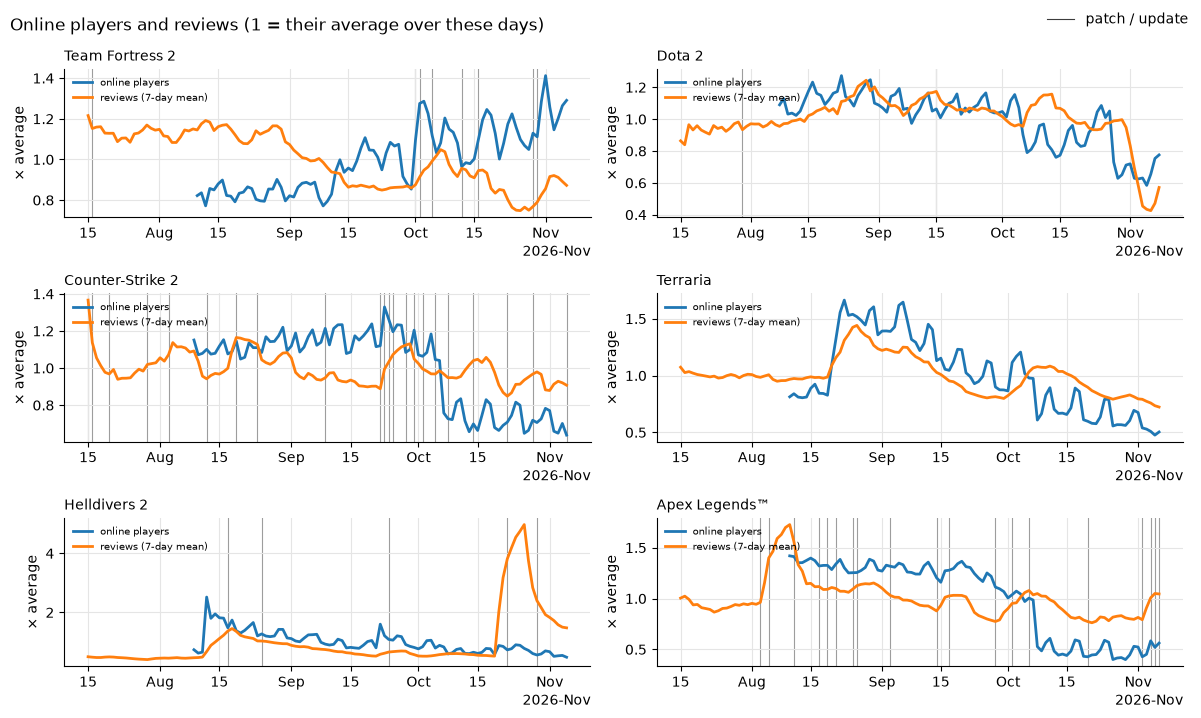

In [8]:
top_games = series.groupby(level="appid")["n"].sum().nlargest(TOP_GAMES).index
daily_online_since = online.loc[online["daily"], "day"].min()
shown = series[series.index.get_level_values("appid").isin(top_games)]
shown = shown[shown.index.get_level_values("day") >= daily_online_since]
lines = pd.DataFrame({
    "online players": shown["players"],
    "reviews (7-day mean)": shown["n"].groupby(level="appid").transform(lambda s: s.rolling(7, min_periods=1).mean()),
})
lines = lines / lines.groupby(level="appid").transform("mean")
per_game_panels(lines, "Online players and reviews (1 = their average over these days)", "× average",
                patches=patch_days(top_games))

**What moves first, daily**: for games with at least 60 days of daily online data, the correlation between today's change in online players and the change in reviews / 👍 share `k` days later, averaged over games. A peak at **k > 0** means players move first; at **k < 0**, reviews move first. Reviews are daily; both players and reviews first lose their weekday rhythm (which they share); the 👍 share is a 7-day mean (daily it is too noisy), which spreads its changes over a week.

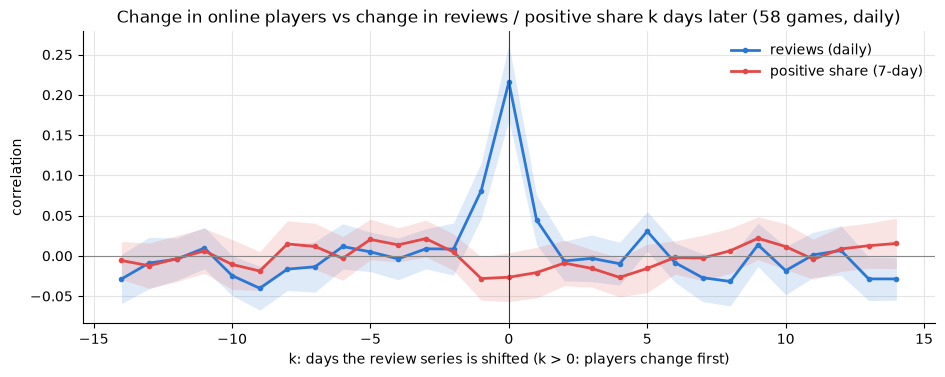

In [9]:
def changes(g):
    """Day-to-day changes of one game's online players, reviews (daily: a rolling mean would make a
    same-day jump look like a lag) and 7-day 👍 share (daily it is too noisy). Players and reviews
    first lose their weekday rhythm (minus the game's mean for that weekday), which both share."""
    def no_weekday(x):
        return x - x.groupby(x.index.dayofweek).transform("mean")

    positive7 = g["n_positive"].rolling(7).sum() / g["n"].rolling(7).sum()
    return pd.DataFrame({"players": no_weekday(np.log(g["players"])).diff(),
                         "reviews": no_weekday(np.log1p(g["n"])).diff(), "positive": positive7.diff()})


daily_games = [a for a in games if series.loc[a, "players"].notna().sum() >= 60]
lags = range(-MAX_LAG, MAX_LAG + 1)
xcorr = {}
for appid in daily_games:
    c = changes(series.loc[appid]).dropna()
    xcorr[appid] = pd.DataFrame({target: [c["players"].corr(c[target].shift(-k)) for k in lags] for target in ["reviews", "positive"]}, index=lags)
mean_xcorr = pd.concat(xcorr).groupby(level=1).agg(["mean", "std", "count"])

fig, ax = plt.subplots(figsize=(11, 3.8))
for target, color in [("reviews", SERIES_COLOR), ("positive", "#e34948")]:
    m, s, n = (mean_xcorr[(target, stat)] for stat in ("mean", "std", "count"))
    ax.plot(m.index, m, marker="o", markersize=3, color=color,
            label="reviews (daily)" if target == "reviews" else "positive share (7-day)")
    ax.fill_between(m.index, m - 1.96 * s / np.sqrt(n), m + 1.96 * s / np.sqrt(n), color=color, alpha=0.15, linewidth=0)
ax.axvline(0, color="#3c3c3c", linewidth=0.8)
ax.axhline(0, color="#888888", linewidth=0.8)
ax.set(xlabel="k: days the review series is shifted (k > 0: players change first)", ylabel="correlation",
       title=f"Change in online players vs change in reviews / positive share k days later ({len(daily_games)} games, daily)")
ax.legend(frameon=False);

**Granger tests** per game on the same daily changes (up to 7 lags): does the past of one series help predict the other beyond its own past? p < 0.05 in many games is evidence of a direction; with ~3 months per game and ~50 games, some hits are expected by chance (5%).

In [10]:
def granger_p(cause, effect, maxlag=7):
    data = pd.concat([effect, cause], axis=1).dropna()
    if len(data) < 40:
        return np.nan
    result = grangercausalitytests(data, maxlag=maxlag)
    return min(r[0]["ssr_ftest"][1] for r in result.values())


rows = []
for appid in daily_games:
    c = changes(series.loc[appid])
    rows.append({"game": names[appid],
                 "positive → players": granger_p(c["positive"], c["players"]),
                 "players → positive": granger_p(c["players"], c["positive"]),
                 "reviews → players": granger_p(c["reviews"], c["players"]),
                 "players → reviews": granger_p(c["players"], c["reviews"])})
granger = pd.DataFrame(rows).set_index("game")
print("share of games with p < 0.05 (by chance: ~5%; min p over 1–7 lags, so somewhat more):")
display((granger < 0.05).mean().to_frame("share of games").style.format("{:.0%}"))

share of games with p < 0.05 (by chance: ~5%; min p over 1–7 lags, so somewhat more):


,share of games
positive → players,5%
players → positive,16%
reviews → players,19%
players → reviews,38%


**Monthly, full history** (SteamCharts' monthly averages before August 2026): does a month with more players than the month before also get more reviews, a better 👍 share? Changes from the previous month (log ratios for players and reviews, points for the 👍 share), not levels: levels of two growing or declining series always correlate. Game-months with at least 30 reviews (`monthly_panel`: a game's first and last month are left out, partial).

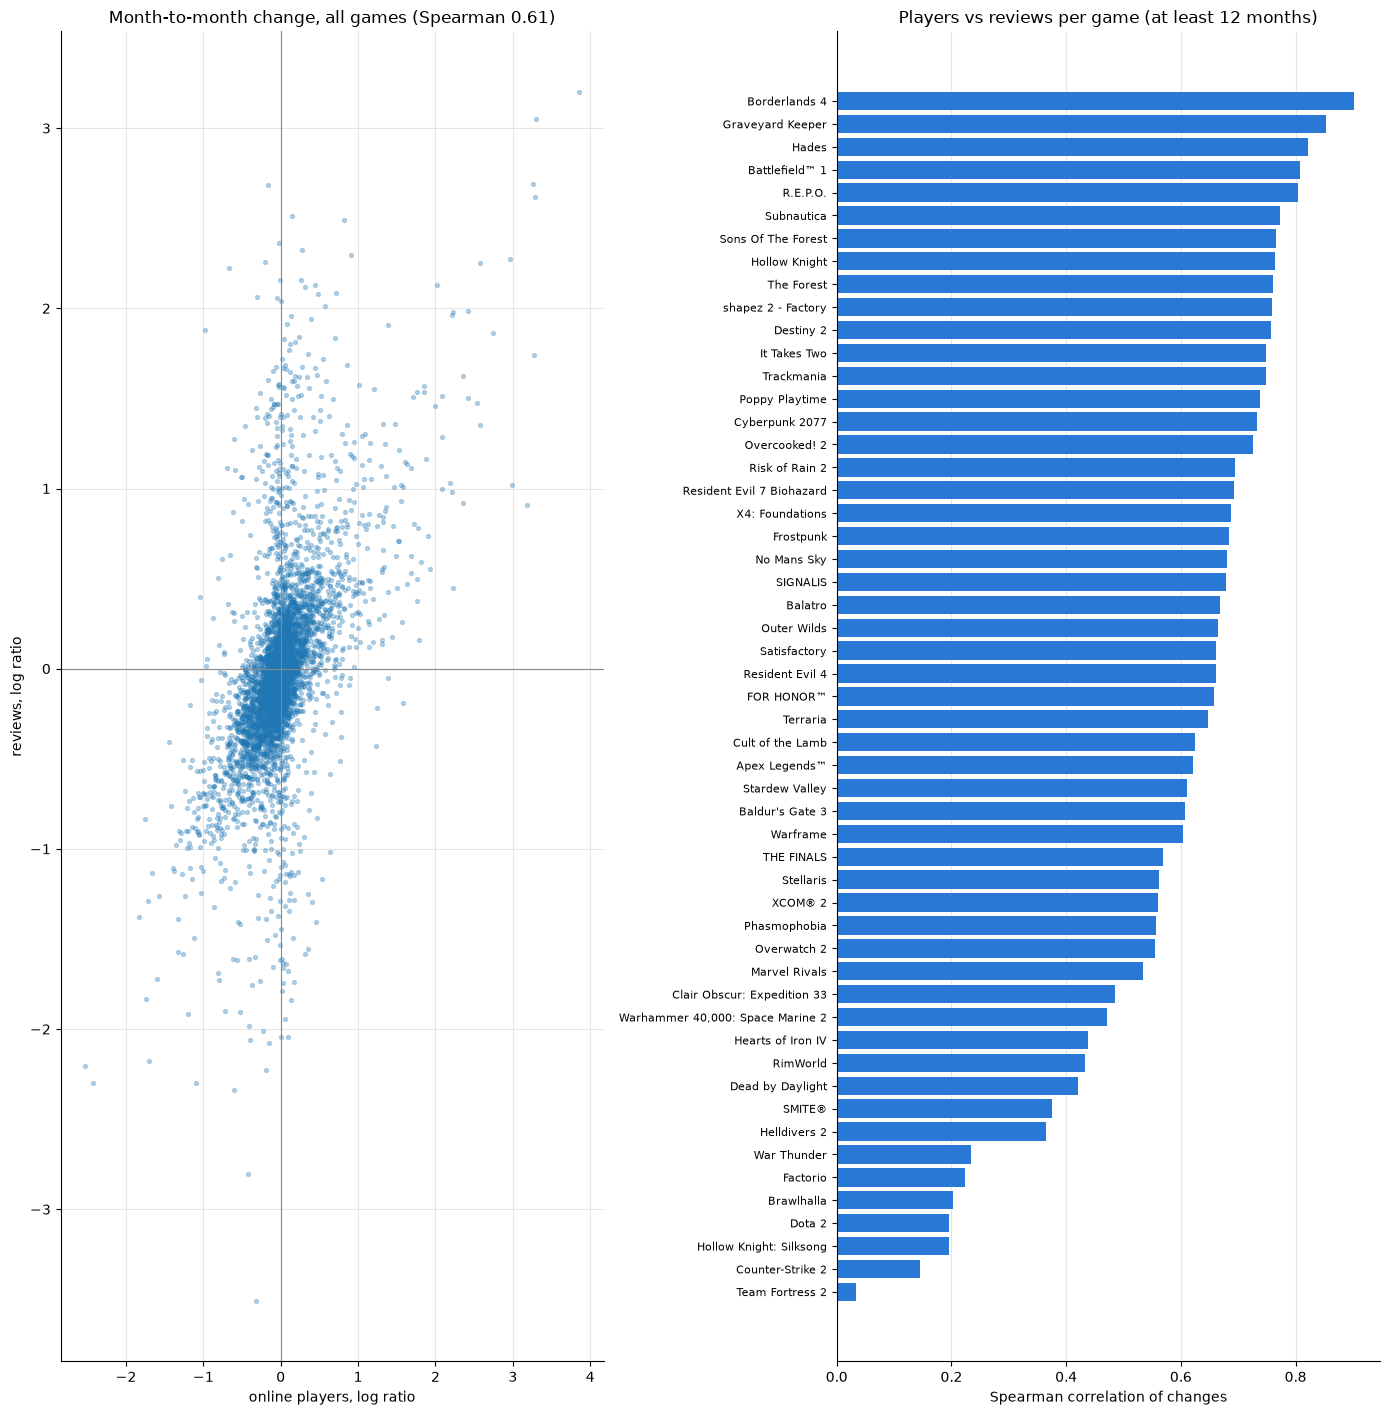

In [11]:
panel = monthly_panel(series, online)
panel = panel[(panel["n"] >= 30) & (panel["players"] > 0)]
monthly_changes = month_changes(pd.DataFrame({"players": np.log(panel["players"]), "reviews": np.log(panel["n"]),
                                              "positive": panel["positive"]})).dropna()
per_game = monthly_changes.groupby(level="appid").apply(
    lambda d: d["players"].corr(d["reviews"], method="spearman") if len(d) >= 12 else np.nan).dropna().sort_values()

fig, axes = plt.subplots(1, 2, figsize=(14, max(4, 0.25 * len(per_game) + 1)))
axes[0].scatter(monthly_changes["players"], monthly_changes["reviews"], s=8, alpha=0.3)
axes[0].axhline(0, color="#888888", linewidth=0.8)
axes[0].axvline(0, color="#888888", linewidth=0.8)
overall = monthly_changes["players"].corr(monthly_changes["reviews"], method="spearman")
axes[0].set(title=f"Month-to-month change, all games (Spearman {overall:.2f})",
            xlabel="online players, log ratio", ylabel="reviews, log ratio")
axes[1].barh(per_game.index.map(names), per_game, color=np.where(per_game > 0, SERIES_COLOR, "#e34948"))
axes[1].set(title="Players vs reviews per game (at least 12 months)", xlabel="Spearman correlation of changes")
axes[1].tick_params(axis="y", labelsize=8)
axes[1].grid(axis="y", visible=False)
fig.tight_layout()

The same changes at lags of −3 to +3 months, pooled over games (k > 0: players change first).

In [12]:
rows = {}
for k in range(-3, 4):
    shifted = monthly_changes[["reviews", "positive"]].groupby(level="appid").shift(-k)
    rows[k] = {target: monthly_changes["players"].corr(shifted[target], method="spearman") for target in ["reviews", "positive"]}
pd.DataFrame(rows).T.rename_axis("k (months; > 0: players change first)").style.format("{:+.2f}").background_gradient(
    cmap="RdBu", vmin=-0.7, vmax=0.7)

,reviews,positive
k (months; > 0: players change first),,
-3,-0.00,+0.00
-2,-0.03,+0.02
-1,-0.12,+0.04
0,+0.61,-0.04
1,-0.05,+0.06
2,-0.09,-0.03
3,-0.01,-0.04
